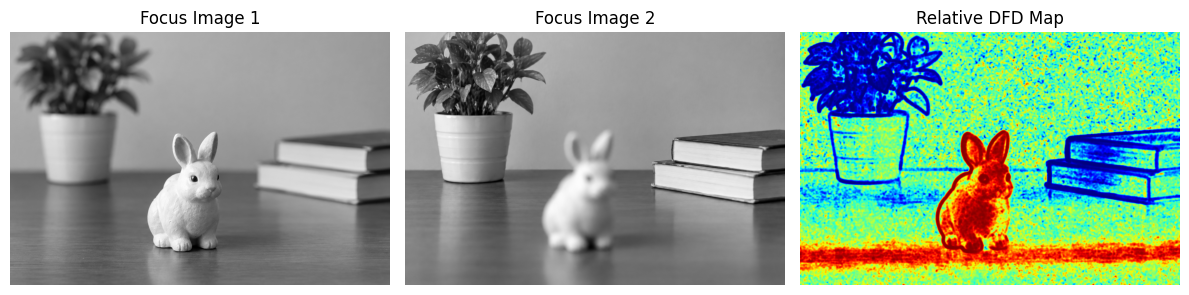

True

In [27]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Read the two images captured at different focus settings
img1 = cv2.imread("/content/Shallow-Focus Bunny Still Life.png", cv2.IMREAD_GRAYSCALE)
img2 = cv2.imread("/content/Blurred Bunny, Crisp Plant and Books.png", cv2.IMREAD_GRAYSCALE)

# 2. Check that both images were loaded
if img1 is None or img2 is None:
    raise FileNotFoundError("Check the image names and file paths.")

# 3. Make both images the same size
img2 = cv2.resize(img2, (img1.shape[1], img1.shape[0]))

# 4. Apply a small Gaussian blur to reduce sensor noise
img1_s = cv2.GaussianBlur(img1, (3, 3), 0)
img2_s = cv2.GaussianBlur(img2, (3, 3), 0)

# 5. Calculate the Laplacian response
lap1 = cv2.Laplacian(img1_s, cv2.CV_64F)
lap2 = cv2.Laplacian(img2_s, cv2.CV_64F)

# 6. Estimate local focus using squared Laplacian
kernel = (15, 15)
focus1 = cv2.GaussianBlur(lap1 ** 2, kernel, 0)
focus2 = cv2.GaussianBlur(lap2 ** 2, kernel, 0)

# 7. Compare the focus measures
eps = 1e-8
focus_diff = (focus1 - focus2) / (focus1 + focus2 + eps)

# 8. Convert the relative focus difference into a displayable map
depth_map = cv2.normalize(focus_diff, None, 0, 255,
                          cv2.NORM_MINMAX).astype(np.uint8)

# 9. Display the input images and the DFD result
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img1, cmap="gray")
plt.title("Focus Image 1")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(img2, cmap="gray")
plt.title("Focus Image 2")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(depth_map, cmap="jet")
plt.title("Relative DFD Map")
plt.axis("off")

plt.tight_layout()
plt.show()

# 10. Save the result
cv2.imwrite("dfd_relative_depth.png", depth_map)



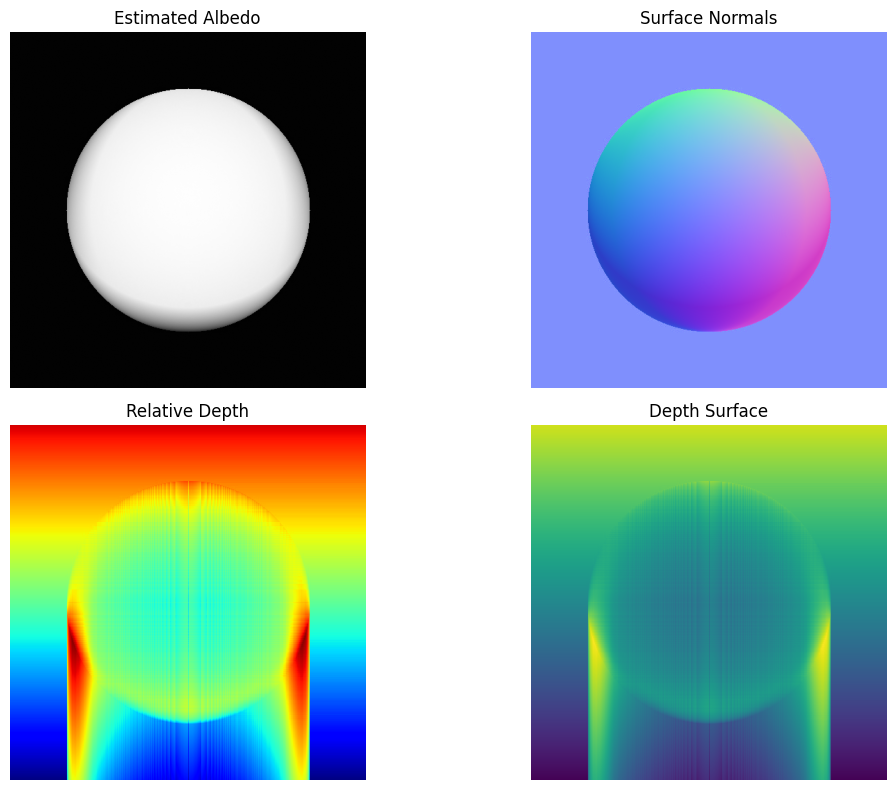

True

In [28]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Read four grayscale images of the same object
files = ["light1.jpg", "light2.jpg", "light3.jpg", "light4.jpg"]

images = []
for f in files:
    img = cv2.imread(f, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(f"Could not read {f}")
    images.append(img.astype(np.float64) / 255.0)

# 2. Stack the images: shape = (number_of_images, height, width)
I = np.stack(images, axis=0)

# 3. Known light directions [lx, ly, lz]
# Replace these with the directions used during your own capture.
L = np.array([
    [ 0.0,  0.0, 1.0],
    [ 0.6,  0.0, 0.8],
    [-0.6,  0.0, 0.8],
    [ 0.0,  0.6, 0.8]
], dtype=np.float64)

# 4. Normalize every light direction
L = L / np.linalg.norm(L, axis=1, keepdims=True)

# 5. Compute the pseudo-inverse of the lighting matrix
L_pinv = np.linalg.pinv(L)

# 6. Rearrange image data so each pixel has an intensity vector
m, h, w = I.shape
I_pixels = I.reshape(m, -1)

# 7. Estimate scaled surface normals g = L+ I
G = L_pinv @ I_pixels

# 8. Calculate albedo = magnitude of the scaled normal
albedo = np.linalg.norm(G, axis=0)

# 9. Normalize G to obtain unit surface normals
normals = G / (albedo[None, :] + 1e-8)

# 10. Extract normal components
nx = normals[0].reshape(h, w)
ny = normals[1].reshape(h, w)
nz = normals[2].reshape(h, w)

# 11. Convert normals to surface gradients
p = -nx / (nz + 1e-8)
q = -ny / (nz + 1e-8)

# 12. Simple path integration to obtain a relative depth map
depth = np.zeros((h, w), dtype=np.float64)

# Integrate p along x direction
for y in range(h):
    depth[y, 1:] = np.cumsum(p[y, :-1])

# Add q contribution along y direction
for x in range(w):
    depth[1:, x] += np.cumsum(q[:-1, x])

# 13. Normalize depth only for visualization
depth_vis = cv2.normalize(depth, None, 0, 255,
                          cv2.NORM_MINMAX).astype(np.uint8)

# 14. Normalize albedo for visualization
albedo_vis = cv2.normalize(albedo.reshape(h, w), None, 0, 255,
                           cv2.NORM_MINMAX).astype(np.uint8)

# 15. Display results
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(albedo_vis, cmap="gray")
plt.title("Estimated Albedo")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(np.dstack([
    (nx + 1) / 2,
    (ny + 1) / 2,
    (nz + 1) / 2
]))
plt.title("Surface Normals")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(depth_vis, cmap="jet")
plt.title("Relative Depth")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(depth, cmap="viridis")
plt.title("Depth Surface")
plt.axis("off")

plt.tight_layout()
plt.show()

# 16. Save outputs
cv2.imwrite("photometric_albedo.png", albedo_vis)
cv2.imwrite("photometric_depth.png", depth_vis)
